# Lab 4 Task 1: Symbol Synchronization

Calculate the timing quantities, run the PSK timing experiment, and interpret BER before and after integer timing-phase recovery.

In [9]:
from pathlib import Path
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
import pandas as pd

def locate_lab_root():
    for base in (Path.cwd(), *Path.cwd().parents):
        if (base / "support" / "lab4_tools.py").is_file():
            return base
    raise FileNotFoundError("Open this notebook from its Lab 4 folder.")

LAB_ROOT = locate_lab_root()
sys.path.insert(0, str(LAB_ROOT / "support"))
WORK_DIR = LAB_ROOT / "work"
FIGURE_DIR = WORK_DIR / "figures"
WAVEFORM_DIR = WORK_DIR / "waveforms"
CAPTURE_DIR = Path(os.environ.get("ECE7377_LAB4_CAPTURE_DIR", WORK_DIR / "captures"))
for path in (FIGURE_DIR, WAVEFORM_DIR, CAPTURE_DIR):
    path.mkdir(parents=True, exist_ok=True)
print("Lab root:", LAB_ROOT)
print("Capture directory:", CAPTURE_DIR)


Lab root: /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab4
Capture directory: /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab4/work/captures


## Required calculations


In [6]:
modulation_orders = (4, 16, 64)
ebn0_db = 15.0
samples_per_symbol = 8
rrc_span_symbols = 10
timing_error_samples = 1

# Complete the communication-system calculations.
bits_per_symbol = {M: int(np.log2(M)) for M in modulation_orders}
esn0_db = {M: ebn0_db + 10 * np.log10(bits_per_symbol[M]) for M in modulation_orders}
rrc_tap_count = rrc_span_symbols * samples_per_symbol + 1
one_filter_delay_samples = (rrc_tap_count - 1) // 2
cascade_delay_samples = 2 * one_filter_delay_samples
timing_error_symbol_fraction = timing_error_samples / samples_per_symbol

print("bits per symbol:", bits_per_symbol)
print("Es/N0 values (dB):", esn0_db)
print("RRC taps:", rrc_tap_count)
print("one-filter and cascade delays:", one_filter_delay_samples, cascade_delay_samples)
print("one-sample error as a symbol fraction:", timing_error_symbol_fraction)

bits per symbol: {4: 2, 16: 4, 64: 6}
Es/N0 values (dB): {4: 18.010299956639813, 16: 21.020599913279625, 64: 22.78151250383644}
RRC taps: 81
one-filter and cascade delays: 40 80
one-sample error as a symbol fraction: 0.125


In [7]:
assert bits_per_symbol == {4: 2, 16: 4, 64: 6}
assert rrc_tap_count == 81
assert one_filter_delay_samples == 40
assert cascade_delay_samples == 80
assert np.isclose(timing_error_symbol_fraction, 0.125)
print("Task 1 calculations passed.")


Task 1 calculations passed.


## Timing study


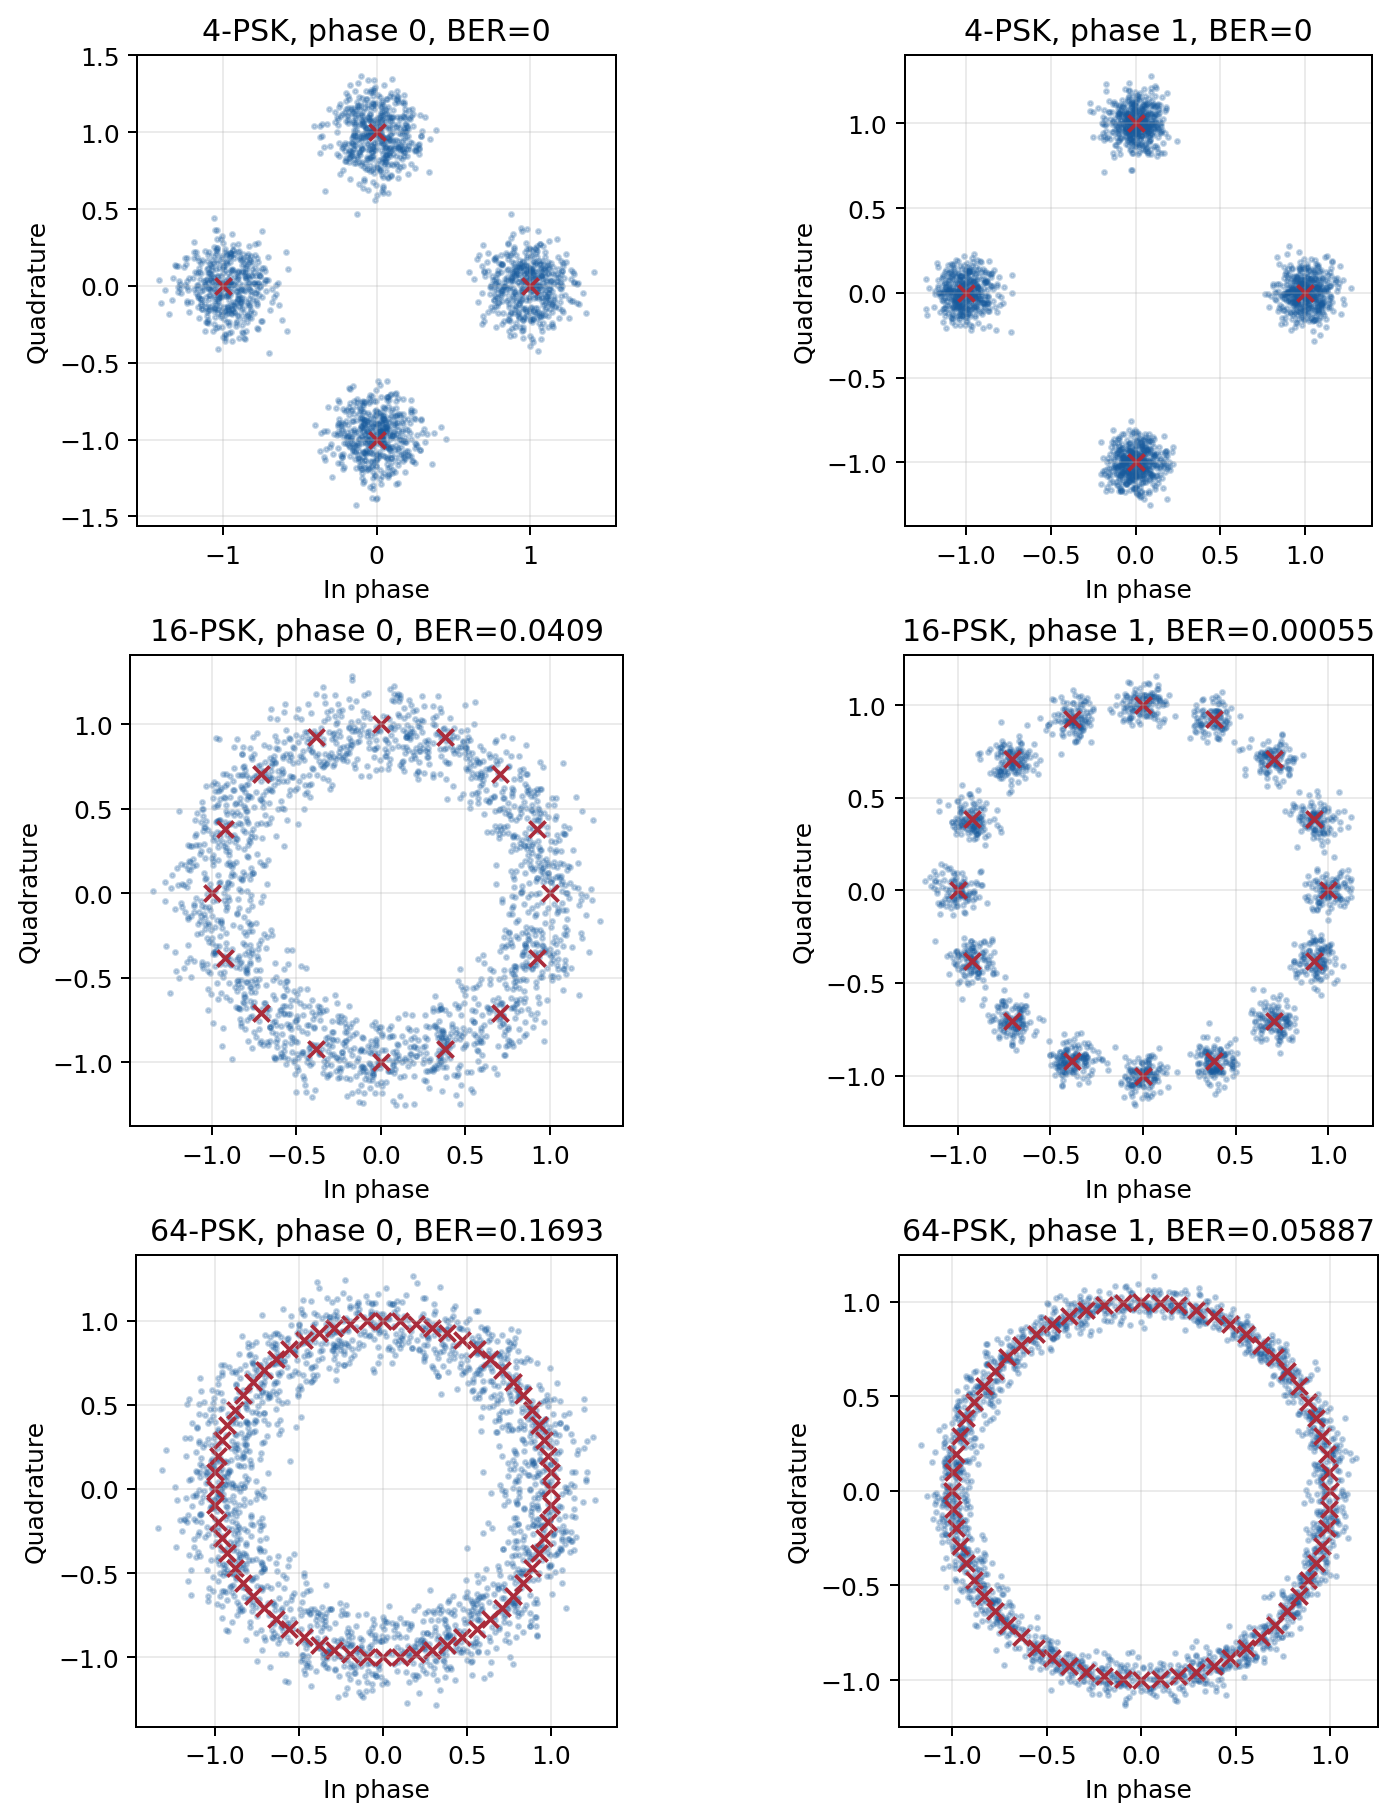

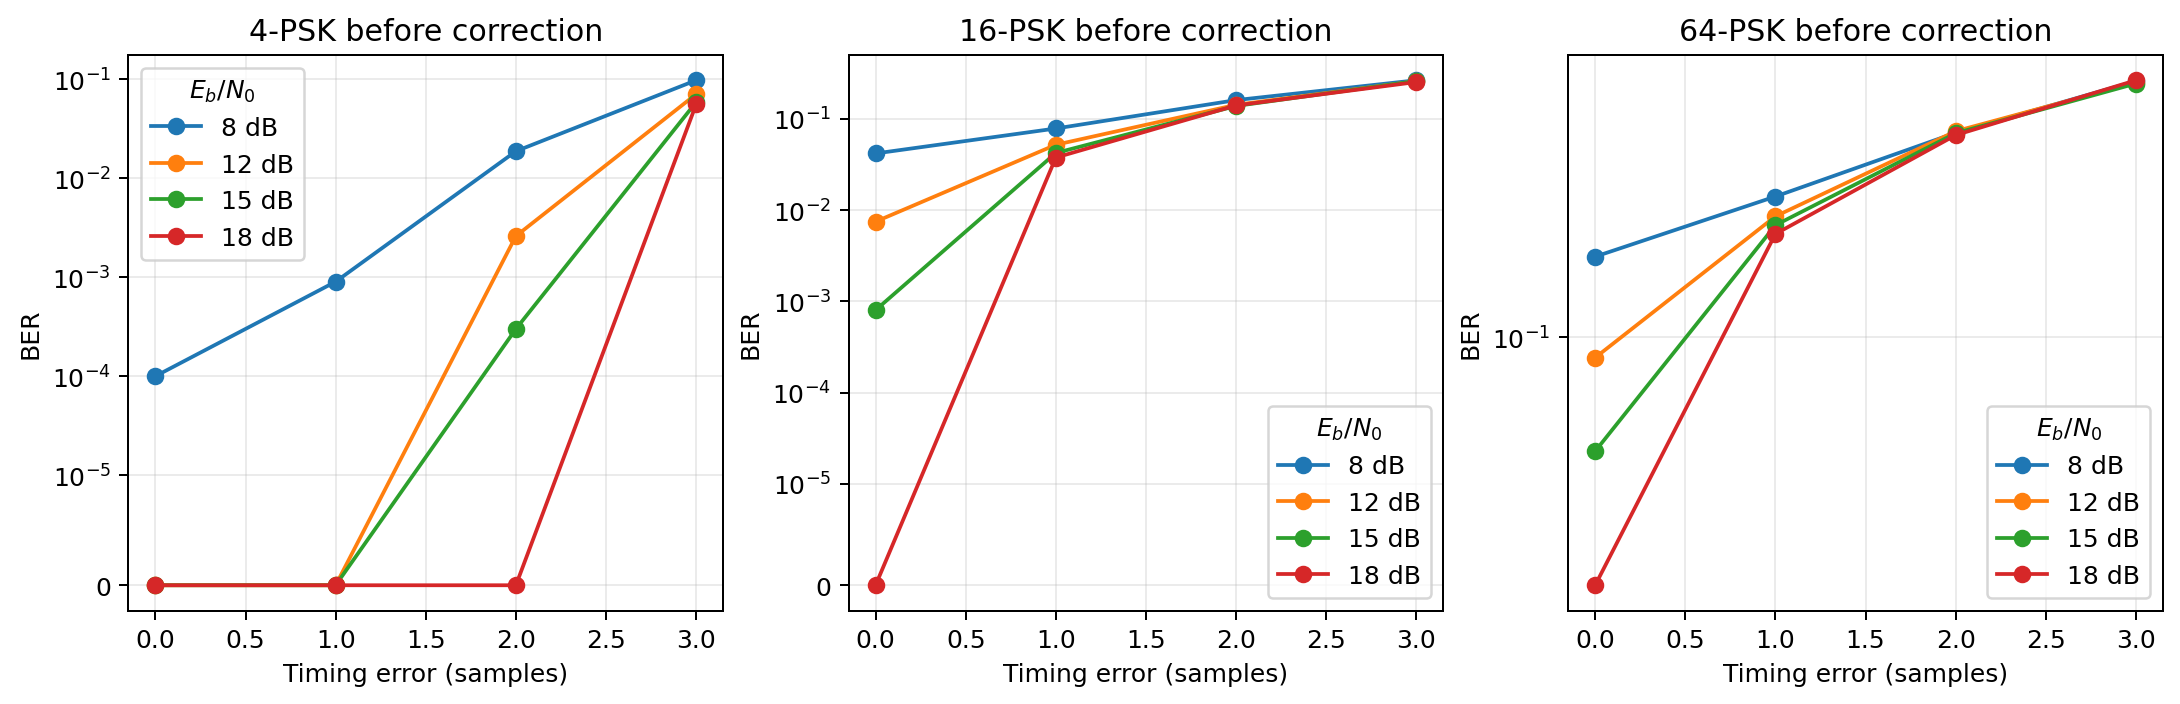

In [11]:
from lab4_tools import plot_timing_study, run_timing_study, save_json

ebn0_values = (8, 12, 15, 18)
timing_errors = (0, 1, 2, 3)
study = run_timing_study(modulation_orders, ebn0_values, timing_errors)
figure_paths = plot_timing_study(study, FIGURE_DIR)
for path in figure_paths:
    display(Image(filename=path))

<span style="color:#165696"><b>Report.</b> Report the true and estimated timing phase for all three modulation orders. </span>

In [10]:
timing_results_df = pd.DataFrame([
    {
        "Modulation": f"{order}-PSK",
        "True Phase": study["single"][order]["true_phase"],
        "Estimated Phase": study["single"][order]["estimated_phase"],
        "BER Before": study["single"][order]["before_ber"],
        "BER After": study["single"][order]["after_ber"],
    }
    for order in modulation_orders
])

display(timing_results_df)

,Modulation,True Phase,Estimated Phase,BER Before,BER After
0,4-PSK,1,1,0.000000,0.000000
1,16-PSK,1,1,0.040900,0.000550
2,64-PSK,1,1,0.169333,0.058867


<span style="color:#165696"><b>Report.</b> 
Explain why timing error produces intersymbol interference. Explain why an off-center sampling instant introduces intersymbol interference. </span>

Timing error causes the receiver to sample the pulse away from its ideal symbol center. At the correct sampling instant, the pulse-shaping and matched filters are designed so that neighboring symbols contribute little or no interference. When sampling occurs off-center, the neighboring pulses are no longer at their zero-crossings, so parts of adjacent symbols contribute to the measured value. This overlap between symbols produces intersymbol interference (ISI) and distorts the received constellation.

<span style="color:#165696"><b>Report.</b> 
Explain why higher-order PSK is more sensitive. Explain why increasing PSK order reduces tolerance to timing error and noise. </span>

Higher-order PSK places more constellation points around the same unit circle, so the angular separation between neighboring symbols becomes smaller. As a result, timing error and noise require less distortion to move a received symbol across a decision boundary. This makes higher-order PSK more likely to decode a symbol incorrectly for the same amount of timing offset or noise. Therefore, increasing the PSK order improves bits per symbol but reduces tolerance to synchronization errors and noise.

<span style="color:#165696"><b>Report.</b> 
Separate the effect of increasing bits per symbol M from the effect of the associated increase in bits per symbol at fixed Eb/N0. Separate the effect of increasing bits per symbol from decreasing angular spacing. </span>

Increasing M increases the number of bits carried by each PSK symbol, since $k=\log_2(M)$. At a fixed $E_b/N_0$, this also increases $E_s/N_0$ because each symbol contains more bits and therefore more energy. However, increasing M also places more constellation points around the same circle, reducing the angular spacing between neighboring symbols. This smaller angular separation is what makes higher-order PSK more sensitive to noise and timing errors, even though the energy per symbol increases.

<span style="color:#165696"><b>Report.</b> 
Discuss how BER changes with the sweep over the timing error and the SNR $E_b/N_0$. </span>

BER increases with timing error because sampling farther from the ideal symbol center introduces more ISI, while BER decreases as the SNR $E_b/N_0$ increases because the signal becomes more robust to noise. The lowest BER is therefore expected at high $E_b/N_0$ and small timing errors, while lower $E_b/N_0$ and larger timing errors produce worse performance. At $E_b/N_0=15$ dB with a one-sample timing error, synchronization reduced BER from 0 to 0 for 4-PSK, 0.0409 to 0.00055 for 16-PSK, and 0.16933 to 0.05887 for 64-PSK. These results show that timing synchronization improves BER, although higher-order PSK remains more sensitive to the combined effects of noise and timing error.